# Importing Libraries

In [1]:
import pandas as pd 
import numpy as np 
import os
import glob as gb
import matplotlib.pyplot as plt 
import cv2




# Setting Up Paths for Train and Test

In [2]:
train_data = "../input/melanoma_cancer_dataset/train"
test_data  = "../input//melanoma_cancer_dataset/test"


# Reading Train Images

In [3]:


train_images = []
train_labels = []
class_ = {'benign': 0, 'malignant': 1}



# open train data folder (os, glob)
for folder in os.listdir(train_data):
    folder_path = os.path.join(train_data, folder)
    
    if os.path.isdir(folder_path):
        print(f"Processing folder: {folder}")
        
        data = gb.glob(os.path.join(folder_path, '*.jpg'))
        print(f"Found {len(data)} images in folder {folder}")
        
        image_count = 0  
        
        # read train images
        for img_path in data:
            image = cv2.imread(img_path)
            if image is not None:
                image_resized = cv2.resize(image, (100, 100))
                train_images.append(image_resized)
                train_labels.append(class_[folder])
                image_count += 1
            else:
                print(f"Warning: Could not read image {img_path}")
        
        print(f"Processed {image_count} images from folder {folder}")
    else:
        print(f"Skipping non-folder item: {folder}")

# Final output
print(f"Total images processed: {len(train_images)}")
print(f"Total labels assigned: {len(train_labels)}")


Processing folder: benign
Found 5000 images in folder benign
Processed 5000 images from folder benign
Processing folder: malignant
Found 4605 images in folder malignant
Processed 4605 images from folder malignant
Total images processed: 9605
Total labels assigned: 9605


# Reading Test Images

In [4]:
test_images = []
test_labels = []

for folder in os.listdir(test_data):
    folder_path = os.path.join(test_data, folder)
    
    if os.path.isdir(folder_path):
        # print(f"Processing folder: {folder}")
        
        data = gb.glob(os.path.join(folder_path, '*.jpg'))
        # print(f"Found {len(data)} images in folder {folder}")
        
        # Read test images
        for img_path in data:
            # print(f"Reading image: {img_path}")
            
            image = cv2.imread(img_path)
            if image is not None:
                image_resized = cv2.resize(image, (100, 100))
                test_images.append(image_resized)
                test_labels.append(class_[folder])
            else:
                print(f"Warning: Could not read image {img_path}")
    else:
        print(f"Skipping non-folder item: {folder}")

print(f"Total images processed: {len(test_images)}")
print(f"Total labels assigned: {len(test_labels)}")


Total images processed: 1000
Total labels assigned: 1000


In [5]:
def get_label(n) : 
    for x , y in class_.items() : 
        if n == y : 
            return x

# Visualisation of Train and Test Images

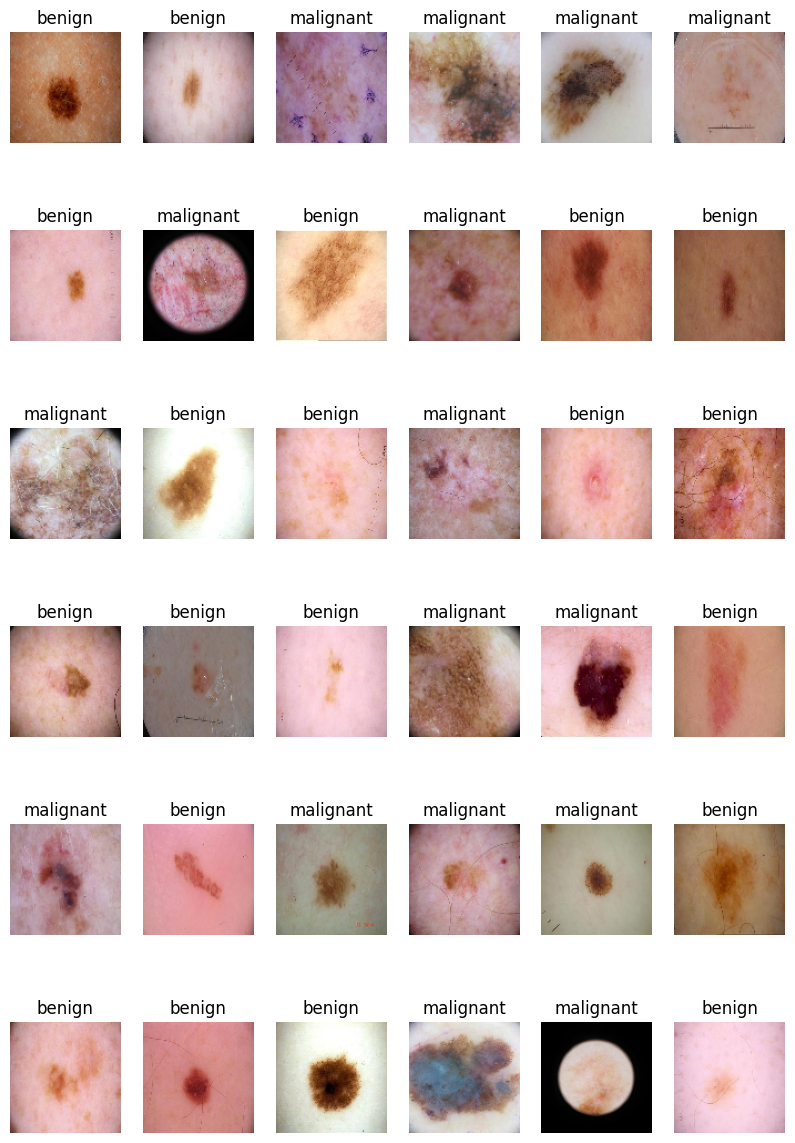

In [6]:
plt.figure(figsize=(10, 15))
for n, i in enumerate(np.random.randint(0, len(train_images), 36)):
    plt.subplot(6, 6, n+1)
    # Convert BGR to RGB if necessary
    img_rgb = cv2.cvtColor(train_images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(get_label(train_labels[i]))
plt.show()

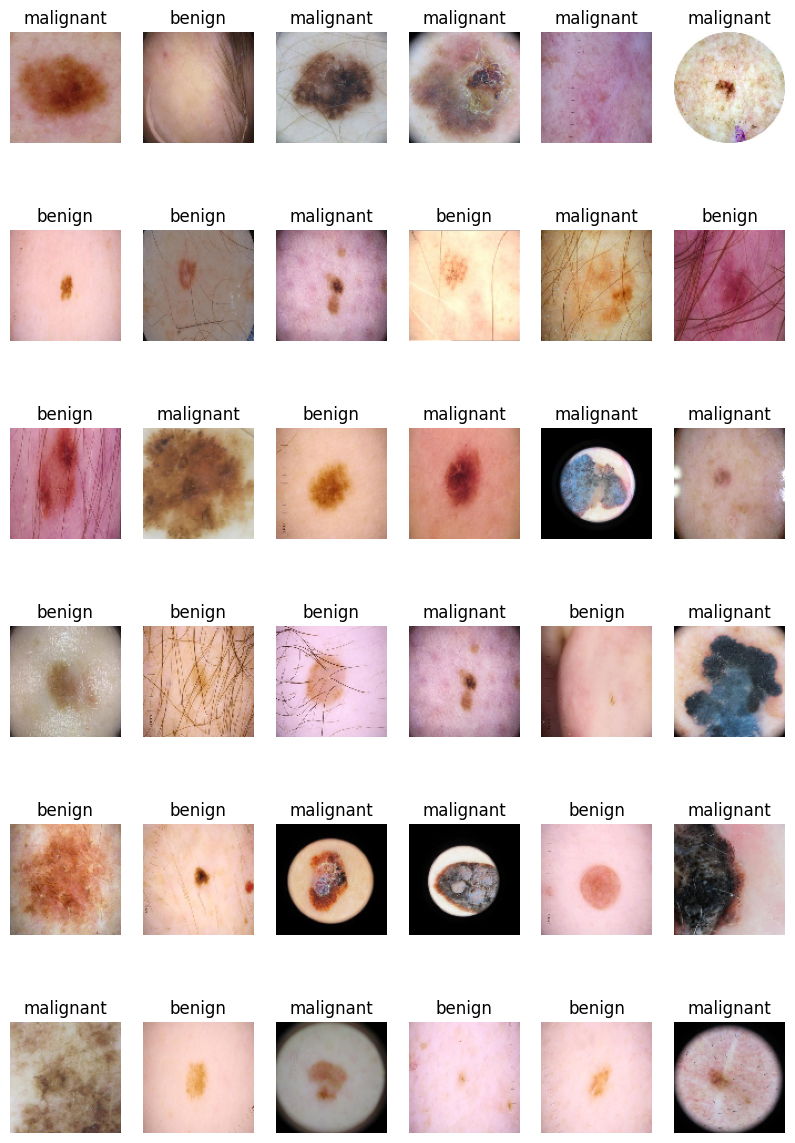

In [7]:
plt.figure(figsize=(10, 15))
for n, i in enumerate(np.random.randint(0, len(test_images), 36)):
    plt.subplot(6, 6, n+1)
    # Convert BGR to RGB if necessary
    img_rgb = cv2.cvtColor(test_images[i], cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(get_label(test_labels[i]))
plt.show()

# RESNET 50

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [10]:
# Convert lists to NumPy arrays
train_images = np.array(train_images)
train_labels = np.array(train_labels)
test_images = np.array(test_images)
test_labels = np.array(test_labels)

print(f"Train images shape: {train_images.shape}")
print(f"Train labels shape: {train_labels.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test labels shape: {test_labels.shape}")

Train images shape: (9605, 100, 100, 3)
Train labels shape: (9605,)
Test images shape: (1000, 100, 100, 3)
Test labels shape: (1000,)


In [11]:
# Normalize the images
train_images = train_images / 255.0
test_images = test_images / 255.0

# Print the shapes to confirm normalization
print(f"Normalized train images shape: {train_images.shape}")
print(f"Normalized test images shape: {test_images.shape}")

Normalized train images shape: (9605, 100, 100, 3)
Normalized test images shape: (1000, 100, 100, 3)


In [12]:


# Convert training images and labels to PyTorch tensors
train_images_tensor = torch.tensor(train_images, dtype=torch.float32).permute(0, 3, 1, 2)  
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

# Convert test images and labels to PyTorch tensors
test_images_tensor = torch.tensor(test_images, dtype=torch.float32).permute(0, 3, 1, 2) 
test_labels_tensor = torch.tensor(test_labels, dtype=torch.long)

# Print shapes to confirm conversion
print(f"Train images tensor shape: {train_images_tensor.shape}")
print(f"Train labels tensor shape: {train_labels_tensor.shape}")
print(f"Test images tensor shape: {test_images_tensor.shape}")
print(f"Test labels tensor shape: {test_labels_tensor.shape}")


Train images tensor shape: torch.Size([9605, 3, 100, 100])
Train labels tensor shape: torch.Size([9605])
Test images tensor shape: torch.Size([1000, 3, 100, 100])
Test labels tensor shape: torch.Size([1000])


In [13]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Create TensorDatasets for training and test datasets
train_dataset = TensorDataset(train_images_tensor, train_labels_tensor)
test_dataset = TensorDataset(test_images_tensor, test_labels_tensor)

# Create DataLoaders for training and test datasets
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Print the number of batches
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of test batches: {len(test_loader)}")


Number of training batches: 301
Number of test batches: 32


In [14]:
from torchvision import datasets, transforms
import torch.optim as optim
import timm
# Data Transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# Dataset and Dataloaders
image_datasets = {
    'train': datasets.ImageFolder(train_data, data_transforms['train']),
    'test': datasets.ImageFolder(test_data, data_transforms['test'])
}
dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=32, shuffle=True),
    'test': DataLoader(image_datasets['test'], batch_size=32, shuffle=False)
}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}
class_names = image_datasets['train'].classes
num_classes = 1


model = timm.create_model('resnet50', pretrained=True, num_classes=num_classes)
model = model.to(device)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

In [15]:
# Freeze all layers except the last one
for param in model.parameters():
    param.requires_grad = False  

# Unfreeze the last layer
for param in model.fc.parameters():  
    param.requires_grad = True

In [16]:
# !pip install torchinfo
from torchinfo import summary
summary(model,
        input_size=(32, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [32, 3, 224, 224]    [32, 1]              --                   Partial
├─Conv2d (conv1)                         [32, 3, 224, 224]    [32, 64, 112, 112]   (9,408)              False
├─BatchNorm2d (bn1)                      [32, 64, 112, 112]   [32, 64, 112, 112]   (128)                False
├─ReLU (act1)                            [32, 64, 112, 112]   [32, 64, 112, 112]   --                   --
├─MaxPool2d (maxpool)                    [32, 64, 112, 112]   [32, 64, 56, 56]     --                   --
├─Sequential (layer1)                    [32, 64, 56, 56]     [32, 256, 56, 56]    --                   False
│    └─Bottleneck (0)                    [32, 64, 56, 56]     [32, 256, 56, 56]    --                   False
│    │    └─Conv2d (conv1)               [32, 64, 56, 56]     [32, 64, 56, 56]     (4,096)              False
│    │    

In [17]:
import time

def train_model(model, criterion, optimizer, num_epochs=10):
    best_acc = 0.0
    best_model_wts = model.state_dict()  # Initialize to save the best model weights
    train_latency = 0.0
    
    # Lists to store metrics for visualization
    train_losses = []
    test_losses = []
    train_accuracies = []
    test_accuracies = []
    test_latencies = []

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)
        
        # Each epoch has a training and testing phase
        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0
            start_time = time.time()
            
            # Iterate over data
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device).float().unsqueeze(1)  # Ensure labels are shaped correctly (batch_size, 1)
                
                # Zero the parameter gradients
                optimizer.zero_grad()

                # Forward pass
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                    # Apply sigmoid for predictions and threshold
                    preds = (torch.sigmoid(outputs) > 0.5).float()  
                    
                    # Backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # Track statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds.view(-1) == labels.view(-1)).item()  # Flatten for comparison

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            
            end_time = time.time()
            latency = end_time - start_time

            # Store metrics
            if phase == 'train':
                train_latency += latency
                train_losses.append(epoch_loss)
                train_accuracies.append(epoch_acc * 100)  # Convert to percentage
            else:
                test_latencies.append(latency)
                test_losses.append(epoch_loss)
                test_accuracies.append(epoch_acc * 100) 

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} Latency: {latency:.4f}s')

            # Deep copy the model
            if phase == 'test' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = model.state_dict()

        print()  # New line for better readability

    # Load best model weights
    model.load_state_dict(best_model_wts)
    print(f'Best Validation Accuracy: {best_acc:.4f}')
    print(f'Training Latency: {train_latency:.4f}s')
    
    # Calculate average test latency
    avg_test_latency = sum(test_latencies) / len(test_latencies) if test_latencies else 0
    print(f'Average Test Latency: {avg_test_latency:.4f}s')

    # Return the trained model and metrics for visualization
    return model, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies

# Call the training function
model, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies = train_model(model, criterion, optimizer)


Epoch 1/10
----------
Train Loss: 0.6462 Acc: 0.7053 Latency: 63.5153s
Test Loss: 0.5940 Acc: 0.8660 Latency: 6.2068s

Epoch 2/10
----------
Train Loss: 0.5689 Acc: 0.8365 Latency: 62.5383s
Test Loss: 0.5279 Acc: 0.8790 Latency: 6.2494s

Epoch 3/10
----------
Train Loss: 0.5128 Acc: 0.8532 Latency: 63.9943s
Test Loss: 0.4938 Acc: 0.8790 Latency: 6.4103s

Epoch 4/10
----------
Train Loss: 0.4761 Acc: 0.8540 Latency: 63.6704s
Test Loss: 0.4458 Acc: 0.8810 Latency: 6.4997s

Epoch 5/10
----------
Train Loss: 0.4454 Acc: 0.8623 Latency: 64.2525s
Test Loss: 0.4157 Acc: 0.8830 Latency: 6.3431s

Epoch 6/10
----------
Train Loss: 0.4229 Acc: 0.8635 Latency: 64.0673s
Test Loss: 0.4053 Acc: 0.8730 Latency: 6.6152s

Epoch 7/10
----------
Train Loss: 0.4027 Acc: 0.8672 Latency: 64.3694s
Test Loss: 0.3819 Acc: 0.8920 Latency: 6.5528s

Epoch 8/10
----------
Train Loss: 0.3877 Acc: 0.8656 Latency: 63.7123s
Test Loss: 0.3750 Acc: 0.8860 Latency: 6.2997s

Epoch 9/10
----------
Train Loss: 0.3773 Acc: 0.

### Saving the Resnet Model

In [18]:
torch.save(model.state_dict(), 'model_weights_RESNET50.pth')

### Getting the Plots

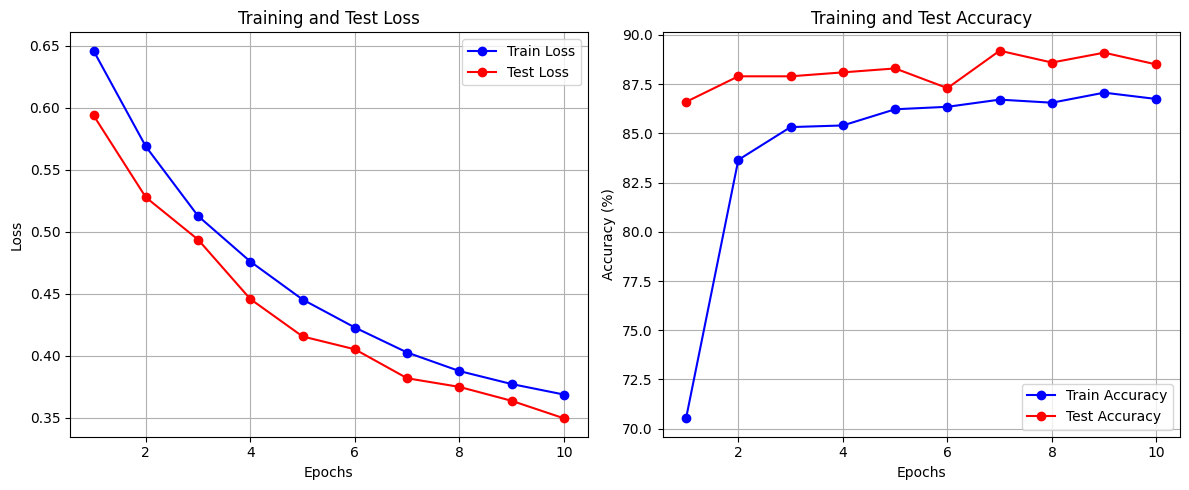

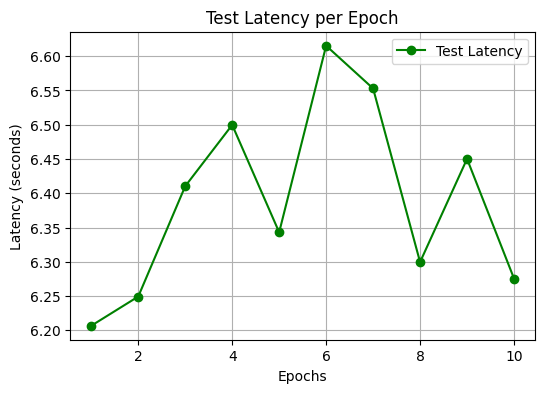

In [19]:
import matplotlib.pyplot as plt

def get_plots(num_epochs, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies):
    
    # Plot Losses
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, num_epochs + 1), train_losses, label='Train Loss', color='blue', marker='o')
    plt.plot(range(1, num_epochs + 1), test_losses, label='Test Loss', color='red', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Test Loss')
    plt.legend()
    plt.grid(True)

    # Plot Accuracies
    plt.subplot(1, 2, 2)
    plt.plot(range(1, num_epochs + 1), train_accuracies, label='Train Accuracy', color='blue', marker='o')
    plt.plot(range(1, num_epochs + 1), test_accuracies, label='Test Accuracy', color='red', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Test Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Plot Latency
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, num_epochs + 1), test_latencies, label='Test Latency', color='green', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Latency (seconds)')
    plt.title('Test Latency per Epoch')
    plt.legend()
    plt.grid(True)
    plt.show()

# Call the updated plotting function with your metrics
get_plots(10, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies)


# USING DINOV2 Vision Transformer

In [20]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import os
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from transformers import Dinov2ForImageClassification

2025-09-06 05:17:31.565298: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757135851.958934      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757135852.062882      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [21]:
train_path = '../input/melanoma_cancer_dataset/train'
test_path = '../input/melanoma_cancer_dataset/test'

In [22]:

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [23]:
# Load datasets using ImageFolder
train_data = ImageFolder(root=train_path, transform=train_transforms)
test_data = ImageFolder(root=test_path, transform=test_transforms)

# Data loaders
train_dataloader = DataLoader(dataset=train_data, batch_size=32, shuffle=True, num_workers=os.cpu_count())
test_dataloader = DataLoader(dataset=test_data, batch_size=32, shuffle=False, num_workers=os.cpu_count())


model = Dinov2ForImageClassification.from_pretrained("facebook/dinov2-base", num_labels=1)
model.to(device)

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of Dinov2ForImageClassification were not initialized from the model checkpoint at facebook/dinov2-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Dinov2ForImageClassification(
  (dinov2): Dinov2Model(
    (embeddings): Dinov2Embeddings(
      (patch_embeddings): Dinov2PatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): Dinov2Encoder(
      (layer): ModuleList(
        (0-11): 12 x Dinov2Layer(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attention): Dinov2Attention(
            (attention): Dinov2SelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): Dinov2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (layer_scale1): Dinov2Laye

In [24]:
# Freeze all layers in the DINOv2 model
for param in model.dinov2.parameters():
    param.requires_grad = False

# Unfreeze the classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [25]:
from torchinfo import summary
summary(model,
        input_size=(32, 3, 224, 224),
        col_names=["input_size", "output_size", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                           Input Shape          Output Shape         Trainable
Dinov2ForImageClassification (Dinov2ForImageClassification)       [32, 3, 224, 224]    [32, 1]              Partial
├─Dinov2Model (dinov2)                                            [32, 3, 224, 224]    [32, 768]            False
│    └─Dinov2Embeddings (embeddings)                              [32, 3, 224, 224]    [32, 257, 768]       False
│    │    └─Dinov2PatchEmbeddings (patch_embeddings)              [32, 3, 224, 224]    [32, 256, 768]       False
│    │    └─Dropout (dropout)                                     [32, 257, 768]       [32, 257, 768]       --
│    └─Dinov2Encoder (encoder)                                    [32, 257, 768]       [32, 257, 768]       False
│    │    └─ModuleList (layer)                                    --                   --                   False
│    └─LayerNorm (layernorm)                                      [32, 257, 768]     

In [26]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

In [27]:
import time
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Initialize metrics lists
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []
test_latencies = []

# Move the model to the appropriate device (GPU or CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

# Training loop
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss = 0
    running_corrects = 0
    total_samples = 0

    # Training phase
    for batch_idx, (images, labels) in enumerate(train_dataloader):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images).logits
        
        # Squeeze outputs to match labels shape
        outputs = outputs.squeeze()
        
        # Calculate loss
        loss = loss_fn(outputs, labels.float())  # Ensure labels are float for BCEWithLogitsLoss
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = (torch.sigmoid(outputs) > 0.5).long()  # Get predictions
        running_corrects += (preds == labels).sum().item()
        total_samples += labels.size(0)

        # Print every 10 batches
        if batch_idx % 10 == 0:
            batch_accuracy = (preds == labels).float().mean()
            print(f"Epoch [{epoch + 1}/{num_epochs}], Batch [{batch_idx}/{len(train_dataloader)}], "
                  f"Loss: {loss.item():.4f}, Batch Accuracy: {batch_accuracy:.4f}")

    # Calculate and store epoch-level metrics
    epoch_loss = running_loss / len(train_dataloader)
    epoch_accuracy = running_corrects / total_samples
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(f"Epoch [{epoch + 1}/{num_epochs}], Average Loss: {epoch_loss:.4f}, "
          f"Epoch Accuracy: {epoch_accuracy:.4f}")

    # Evaluation on test data
    model.eval()
    test_running_loss = 0
    test_running_corrects = 0
    test_total_samples = 0
    start_time = time.time()

    with torch.no_grad():
        for images, labels in test_dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images).logits
            
            # Squeeze outputs for consistency
            outputs = outputs.squeeze()  # Shape [32]
            loss = loss_fn(outputs, labels.float())  # Ensure labels are float

            test_running_loss += loss.item()
            preds = (torch.sigmoid(outputs) > 0.5).long()
            test_running_corrects += (preds == labels).sum().item()
            test_total_samples += labels.size(0)

    end_time = time.time()
    test_loss = test_running_loss / len(test_dataloader)
    test_accuracy = test_running_corrects / test_total_samples
    latency = end_time - start_time

    # Store test metrics
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)
    test_latencies.append(latency)

    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}, Latency: {latency:.4f}s")


Epoch [1/10], Batch [0/301], Loss: 0.8374, Batch Accuracy: 0.4062
Epoch [1/10], Batch [10/301], Loss: 0.6074, Batch Accuracy: 0.7188
Epoch [1/10], Batch [20/301], Loss: 0.6484, Batch Accuracy: 0.6562
Epoch [1/10], Batch [30/301], Loss: 0.5795, Batch Accuracy: 0.6875
Epoch [1/10], Batch [40/301], Loss: 0.5802, Batch Accuracy: 0.6875
Epoch [1/10], Batch [50/301], Loss: 0.5116, Batch Accuracy: 0.7812
Epoch [1/10], Batch [60/301], Loss: 0.5235, Batch Accuracy: 0.8438
Epoch [1/10], Batch [70/301], Loss: 0.4425, Batch Accuracy: 0.8438
Epoch [1/10], Batch [80/301], Loss: 0.4965, Batch Accuracy: 0.8125
Epoch [1/10], Batch [90/301], Loss: 0.4088, Batch Accuracy: 0.8438
Epoch [1/10], Batch [100/301], Loss: 0.3869, Batch Accuracy: 0.8438
Epoch [1/10], Batch [110/301], Loss: 0.5143, Batch Accuracy: 0.6875
Epoch [1/10], Batch [120/301], Loss: 0.4150, Batch Accuracy: 0.8125
Epoch [1/10], Batch [130/301], Loss: 0.2551, Batch Accuracy: 0.9375
Epoch [1/10], Batch [140/301], Loss: 0.3390, Batch Accuracy

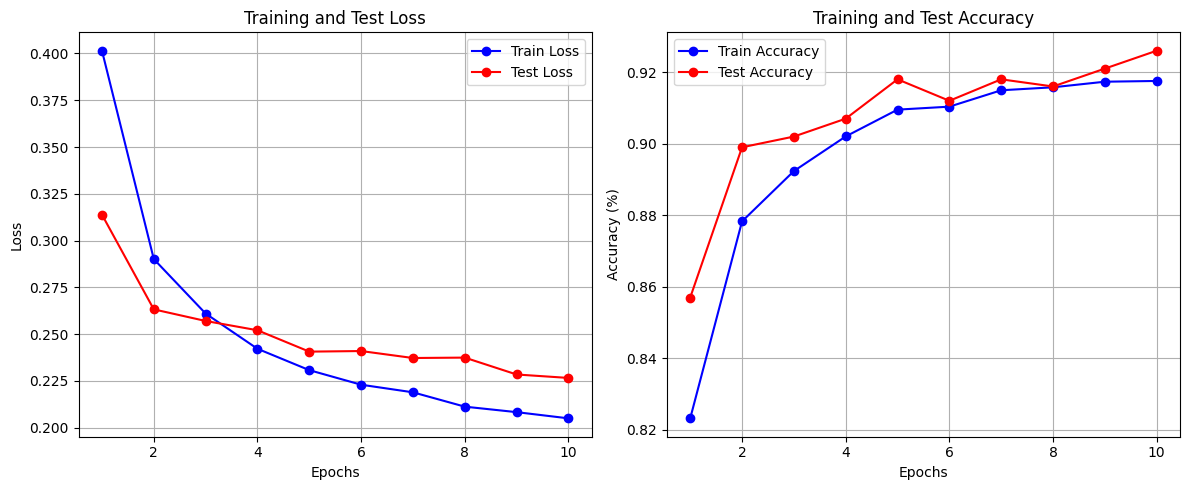

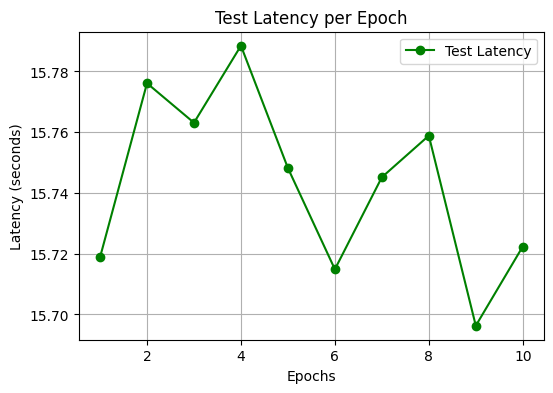

In [28]:

def get_plots(num_epochs, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies):
    # Plot Losses
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(range(1, num_epochs + 1), train_losses, label='Train Loss', color='blue', marker='o')
    plt.plot(range(1, num_epochs + 1), test_losses, label='Test Loss', color='red', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Test Loss')
    plt.legend()
    plt.grid(True)

    # Plot Accuracies
    plt.subplot(1, 2, 2)
    plt.plot(range(1, num_epochs + 1), train_accuracies, label='Train Accuracy', color='blue', marker='o')
    plt.plot(range(1, num_epochs + 1), test_accuracies, label='Test Accuracy', color='red', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Test Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Plot Latency
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, num_epochs + 1), test_latencies, label='Test Latency', color='green', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('Latency (seconds)')
    plt.title('Test Latency per Epoch')
    plt.legend()
    plt.grid(True)
    plt.show()


get_plots(num_epochs, train_losses, test_losses, train_accuracies, test_accuracies, test_latencies)

### Saving the model

In [29]:

torch.save(model.state_dict(), 'dinov2_finetuned.pth')


# Evaluating

In [30]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay


# Load the pre-trained DINOv2 model for binary classification
model_dino = Dinov2ForImageClassification.from_pretrained("facebook/dinov2-base", num_labels=1)
model_dino.classifier = torch.nn.Linear(model_dino.classifier.in_features, 1)
model_dino.load_state_dict(torch.load('dinov2_finetuned.pth'))

for param in model_dino.dinov2.parameters():
    param.requires_grad = False  

# Ensure the classifier is trainable
for param in model_dino.classifier.parameters():
    param.requires_grad = True  

# Load the ResNet50 model for binary classification
num_classes = 1
model_resnet = timm.create_model('resnet50', pretrained=False, num_classes=num_classes)
model_resnet.load_state_dict(torch.load('/kaggle/working/model_weights_RESNET50.pth', map_location=torch.device("cuda" if torch.cuda.is_available() else "cpu")))

for param in model_resnet.parameters():
    param.requires_grad = False  

# Unfreeze the last layer
for param in model_resnet.fc.parameters():  
    param.requires_grad = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_dino.to(device)
model_resnet.to(device)

summary(model_dino,
        input_size=(32, 3, 224, 224),
        col_names=["input_size", "output_size", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Some weights of Dinov2ForImageClassification were not initialized from the model checkpoint at facebook/dinov2-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Layer (type (var_name))                                           Input Shape          Output Shape         Trainable
Dinov2ForImageClassification (Dinov2ForImageClassification)       [32, 3, 224, 224]    [32, 1]              Partial
├─Dinov2Model (dinov2)                                            [32, 3, 224, 224]    [32, 768]            False
│    └─Dinov2Embeddings (embeddings)                              [32, 3, 224, 224]    [32, 257, 768]       False
│    │    └─Dinov2PatchEmbeddings (patch_embeddings)              [32, 3, 224, 224]    [32, 256, 768]       False
│    │    └─Dropout (dropout)                                     [32, 257, 768]       [32, 257, 768]       --
│    └─Dinov2Encoder (encoder)                                    [32, 257, 768]       [32, 257, 768]       False
│    │    └─ModuleList (layer)                                    --                   --                   False
│    └─LayerNorm (layernorm)                                      [32, 257, 768]     

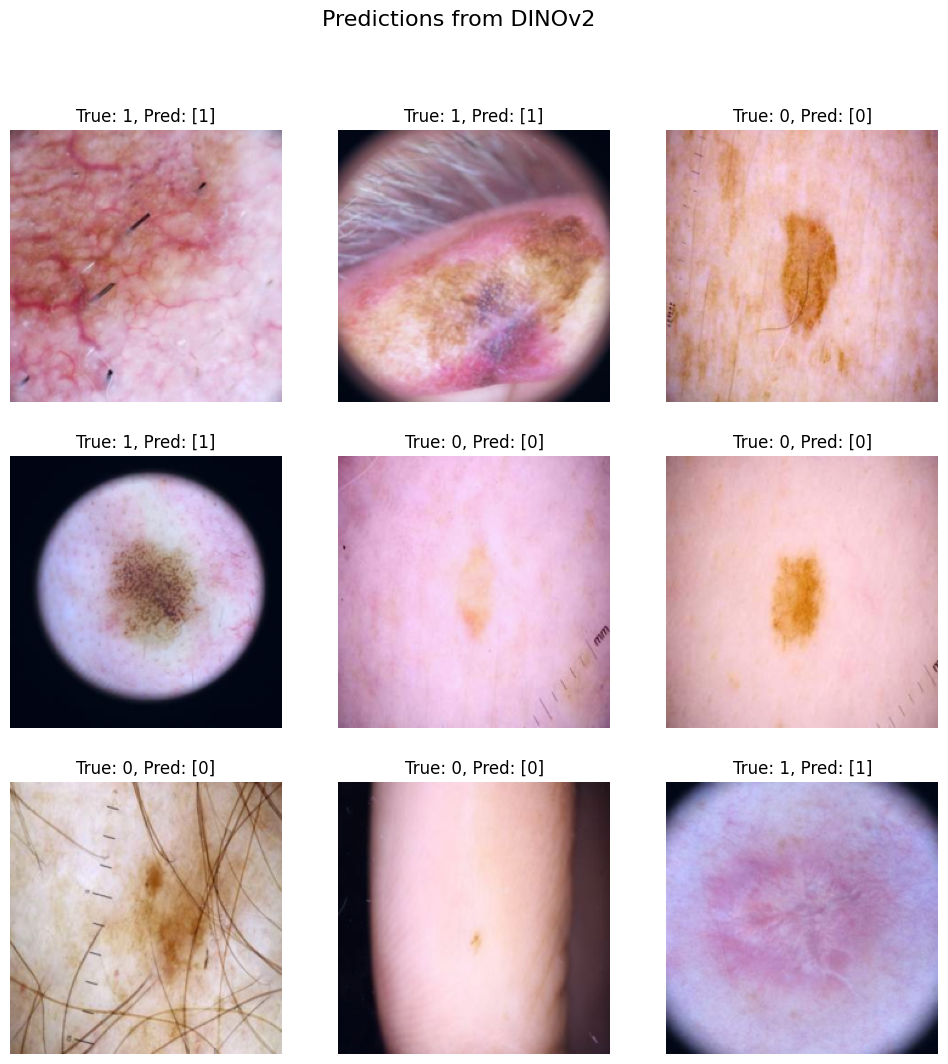

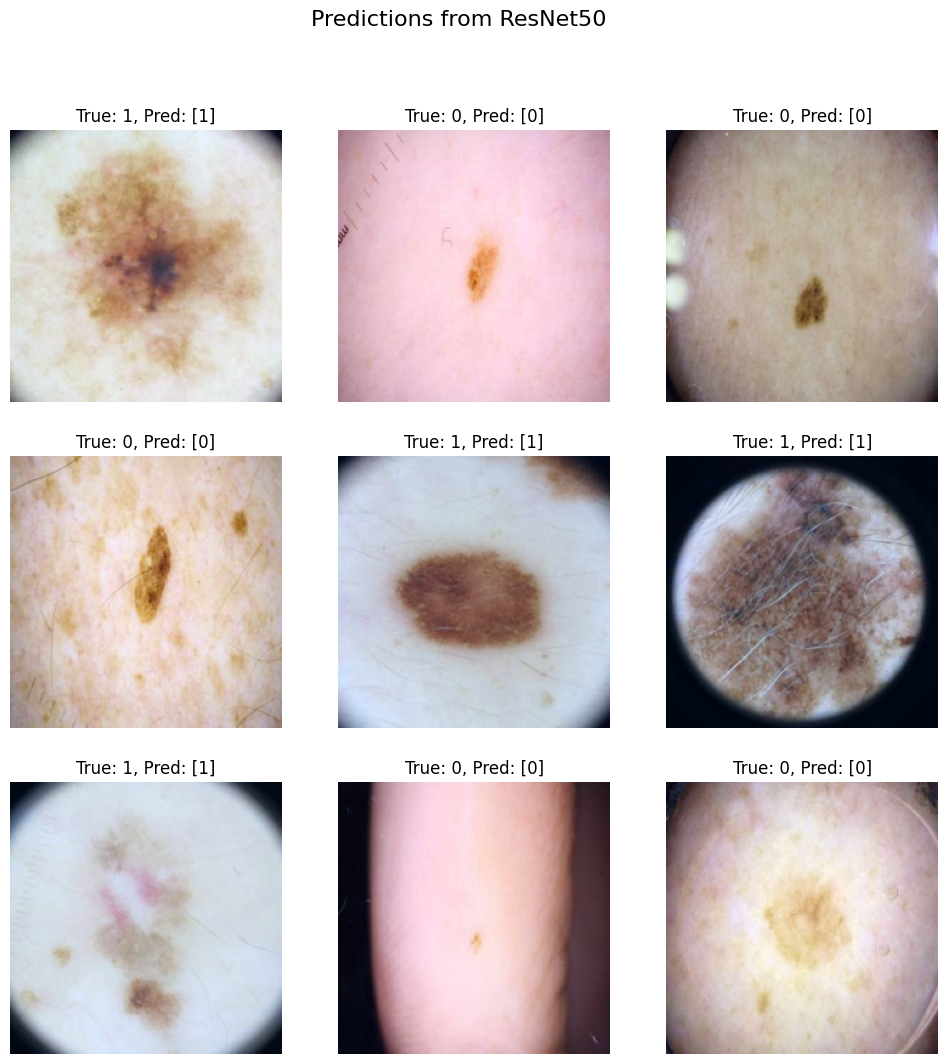

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


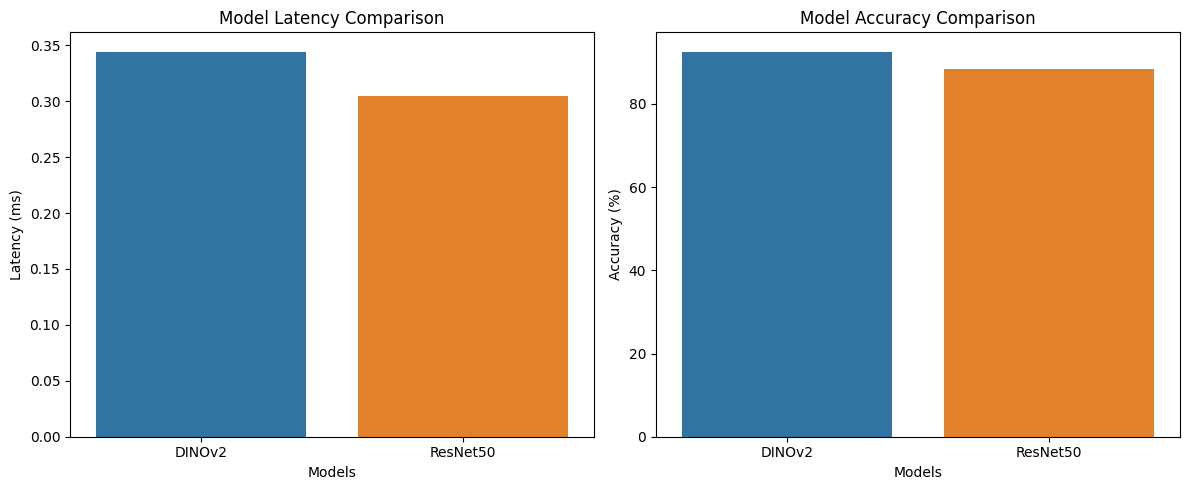

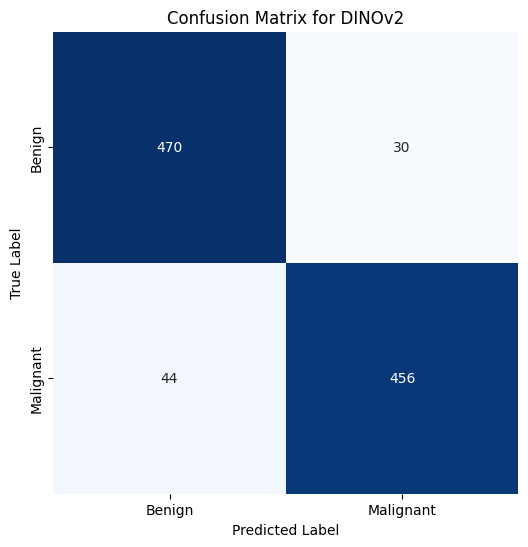

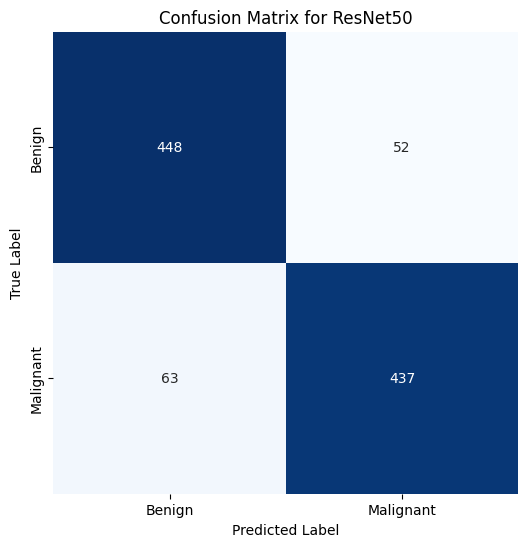

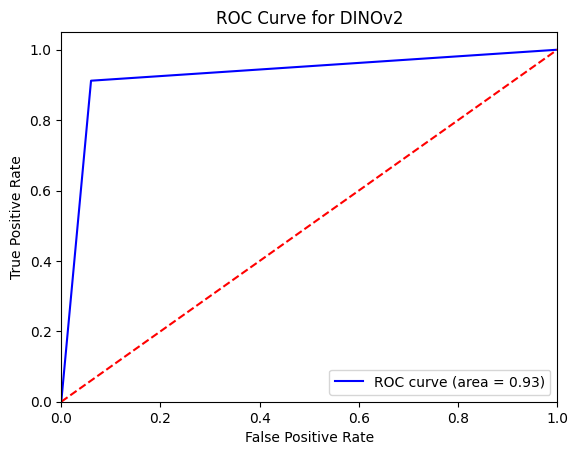

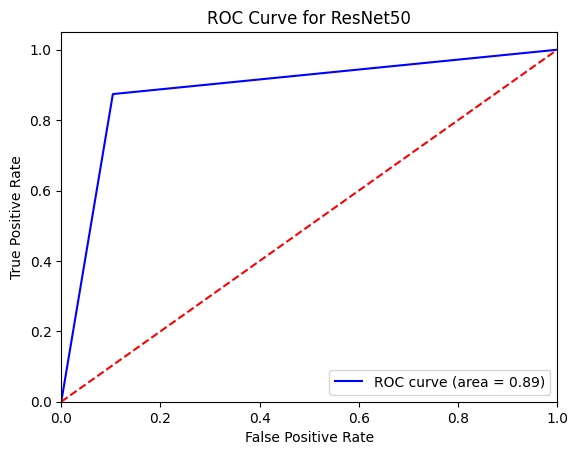

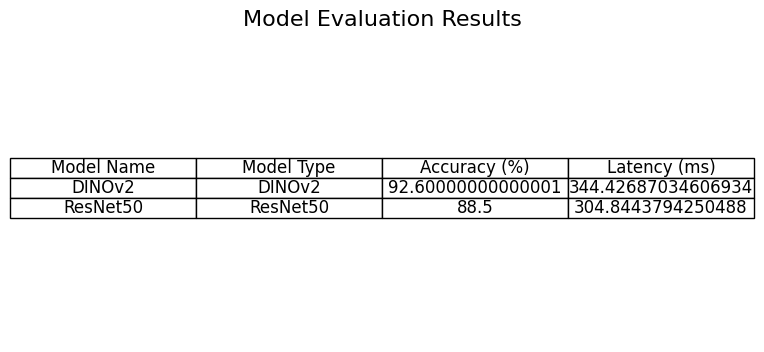

In [31]:
import random
def evaluate_model(model, dataloader, device):
    model.eval()
    running_corrects = 0
    total_samples = 0
    total_latency = 0
    all_preds = []
    all_labels = []
    all_images = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            start_time = time.time()
            outputs = model(images)
            end_time = time.time()

            total_latency += (end_time - start_time) * 1000  # Convert to milliseconds

            if hasattr(outputs, 'logits'):
                logits = outputs.logits
            else:
                logits = outputs  # For ResNet50 or other models

            preds = torch.sigmoid(logits)
            preds = (preds > 0.5).long()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_images.extend(images.cpu().numpy())  # Store images for display

            running_corrects += (preds.view(-1) == labels).sum().item()
            total_samples += labels.size(0)

    accuracy = (running_corrects / total_samples) * 100
    avg_latency = total_latency / total_samples if total_samples > 0 else 0

    return accuracy, avg_latency, all_labels, all_preds, all_images

# Evaluate both models
dino_accuracy, dino_latency, dino_labels, dino_preds, dino_images = evaluate_model(model_dino, test_dataloader, device)
resnet_accuracy, resnet_latency, resnet_labels, resnet_preds, resnet_images = evaluate_model(model_resnet, test_dataloader, device)

# Prepare data for plotting
losses = {'DINOv2': dino_latency, 'ResNet50': resnet_latency}
accuracies = {'DINOv2': dino_accuracy, 'ResNet50': resnet_accuracy}

# Function to display images and predictions
def display_predictions(images, labels, preds, model_name):
    plt.figure(figsize=(12, 12))
    random_indices = random.sample(range(len(images)), min(9, len(images)))  # Random selection of images
    for i in random_indices:
        plt.subplot(3, 3, random_indices.index(i) + 1)
        img = images[i].transpose(1, 2, 0)  # Transpose to get (H, W, C)
        img = (img - img.min()) / (img.max() - img.min())  # Normalize to [0, 1]
        
        plt.imshow(img)  # Use the RGB image
        plt.title(f'True: {labels[i]}, Pred: {preds[i]}')
        plt.axis('off')
    plt.suptitle(f'Predictions from {model_name}', fontsize=16)
    plt.show()

# Display predictions for both models
display_predictions(dino_images, dino_labels, dino_preds, 'DINOv2')
display_predictions(resnet_images, resnet_labels, resnet_preds, 'ResNet50')

# Function to plot comparison graphs
def plot_comparison_graphs(losses, accuracies):
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    sns.barplot(x=list(losses.keys()), y=list(losses.values()))
    plt.title('Model Latency Comparison')
    plt.ylabel('Latency (ms)')
    plt.xlabel('Models')

    plt.subplot(1, 2, 2)
    sns.barplot(x=list(accuracies.keys()), y=list(accuracies.values()))
    plt.title('Model Accuracy Comparison')
    plt.ylabel('Accuracy (%)')
    plt.xlabel('Models')

    plt.tight_layout()
    plt.show()

# Plot comparisons
plot_comparison_graphs(losses, accuracies)

# Confusion matrix plot function
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    plt.title(f'Confusion Matrix for {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

# Plot confusion matrices
plot_confusion_matrix(dino_labels, dino_preds, 'DINOv2')
plot_confusion_matrix(resnet_labels, resnet_preds, 'ResNet50')

# ROC curve plot function
def plot_roc_curve(y_true, y_pred, model_name):
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)
    
    plt.figure()
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='red', linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name}')
    plt.legend(loc='lower right')
    plt.show()

# Plot ROC curves
plot_roc_curve(dino_labels, dino_preds, 'DINOv2')
plot_roc_curve(resnet_labels, resnet_preds, 'ResNet50')



# Model evaluation results
model_names = ['DINOv2', 'ResNet50']
model_types = ['DINOv2', 'ResNet50']
accuracies = [dino_accuracy, resnet_accuracy]
latencies = [dino_latency, resnet_latency]  # in seconds

# Create a DataFrame
results_df = pd.DataFrame({
    'Model Name': model_names,
    'Model Type': model_types,
    'Accuracy (%)': accuracies,
    'Latency (ms)': [lat * 1000 for lat in latencies]  
})


plt.figure(figsize=(8, 4))
plt.axis('off')
table = plt.table(cellText=results_df.values,
                  colLabels=results_df.columns,
                  cellLoc='center', 
                  loc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.2)  # Scale table size
plt.title('Model Evaluation Results', fontsize=16)
plt.show()
